In [3]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
from path_setup import setup_project_path
setup_project_path()
base_dir = r"C:\Users\acostamendoza\projects\distance-project\radial-analysis"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.workflows import load_dataframe, analyze_session, batch_analyze_sessions, combine_animal_sessions, batch_combine_and_export, WidefieldAligner
from src.viz.SessionVisualizer import MultiSessionVisualizer
from src.viz.WidefieldVisualizer import WidefieldVisualizer
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM045'
experiment_name = 'tiling_120um'

combined_df = load_dataframe(mouse_name=mouse_name, experiment_name=experiment_name)
viz = MultiSessionVisualizer(combined_df, mouse_name=mouse_name, experiment_name='tiling_120um')
wf = WidefieldVisualizer(mouse_name, 'tiling_120um')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[ok] Loaded DataFrame from D:/data-distance-coding-project/multi-session-data\SAM045_tiling_120um\SAM045_tiling_120um_combined_sessions.pkl (19534 cells)
Alignment parameters loaded from: D:/data-distance-coding-project/multi-session-data/SAM045_tiling_120um\SAM045_tiling_120um_alignment_parameters.pkl


# 1. Checking Alignment is right

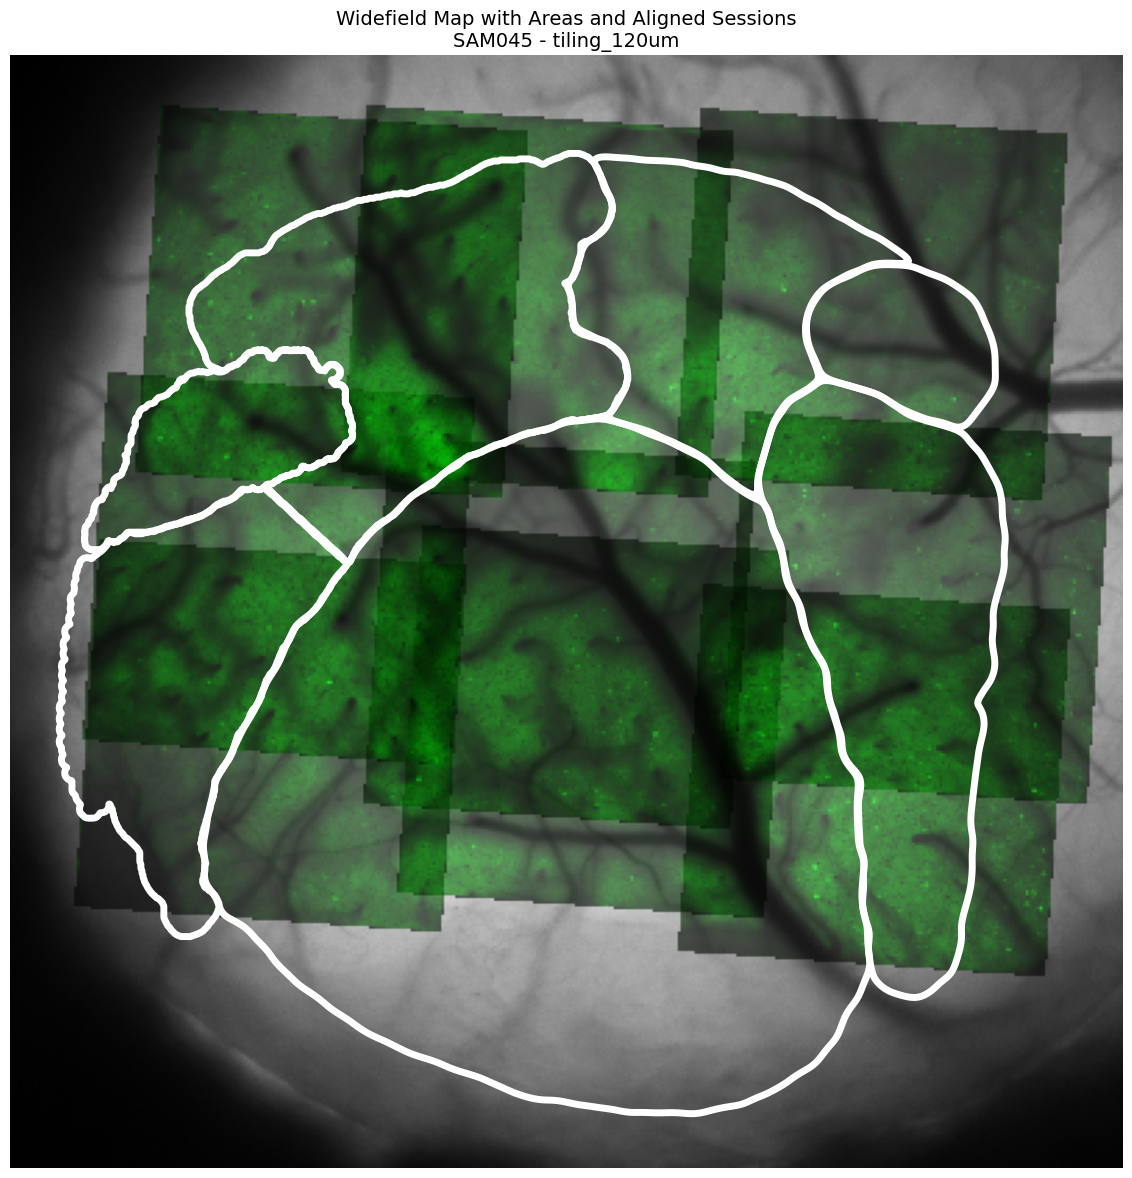

(<Figure size 1200x1200 with 1 Axes>,
 <Axes: title={'center': 'Widefield Map with Areas and Aligned Sessions\nSAM045 - tiling_120um'}>)

In [4]:
wf.plot_widefield_with_areas_and_sessions()

[reliable] colored: 5010, gray: 8909, total: 13919 (36.0% colored)


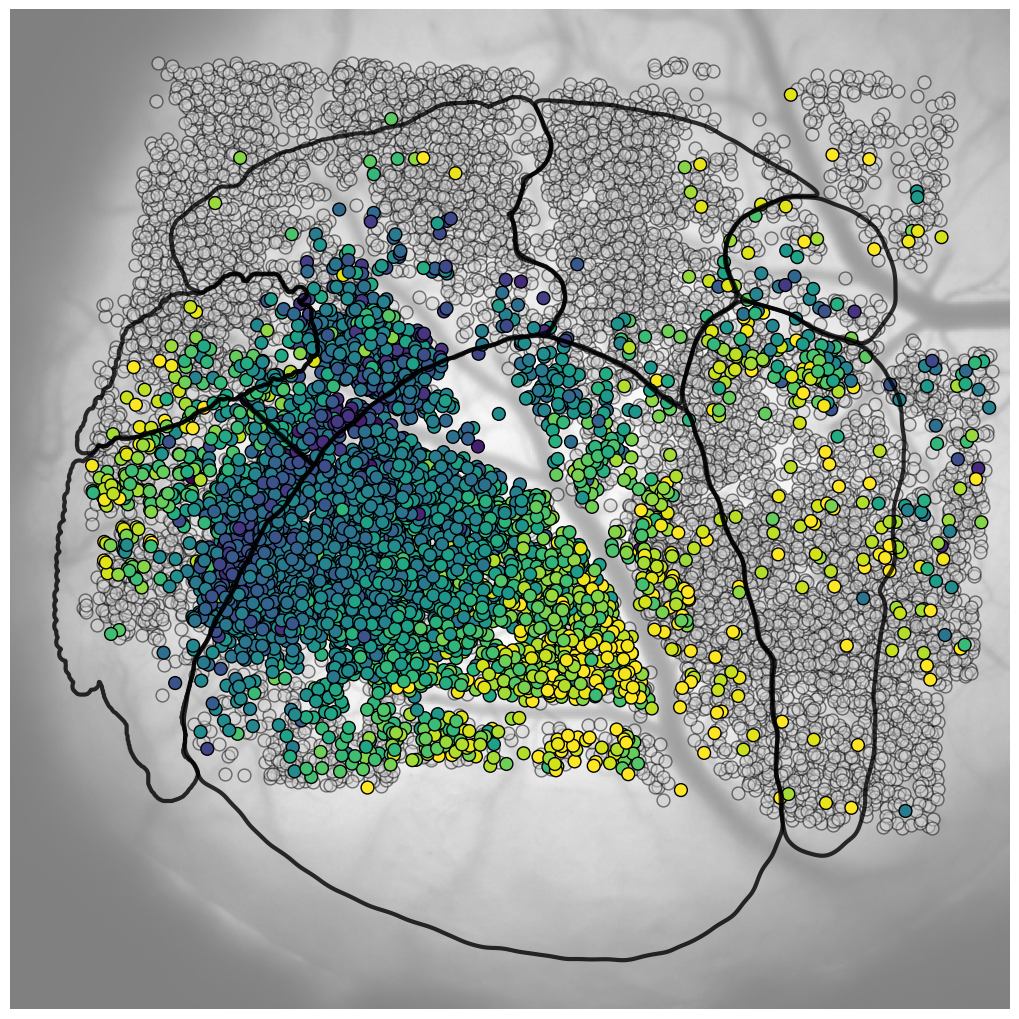

In [5]:
fig, ax = viz.plot_cell_features(condition='reliable', feature='RF')

# 2. Stats of responsive and modulated cells

C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\viz\SessionVisualizer.py:360: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(groups, rotation=45, ha='right')


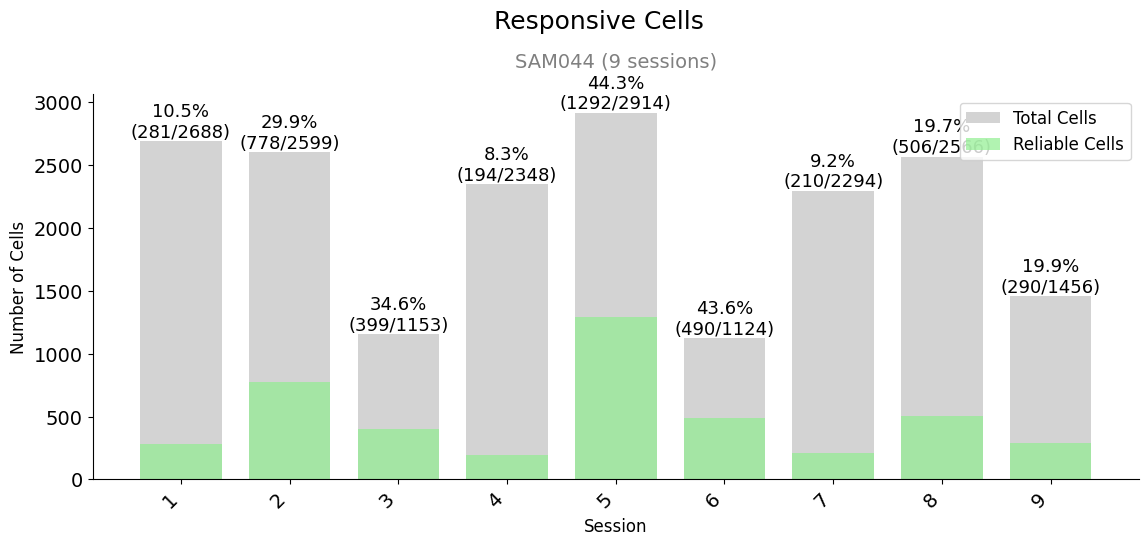

In [170]:
fig = viz.plot_responsive_bars(group_by='session')

C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\viz\SessionVisualizer.py:360: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(groups, rotation=45, ha='right')


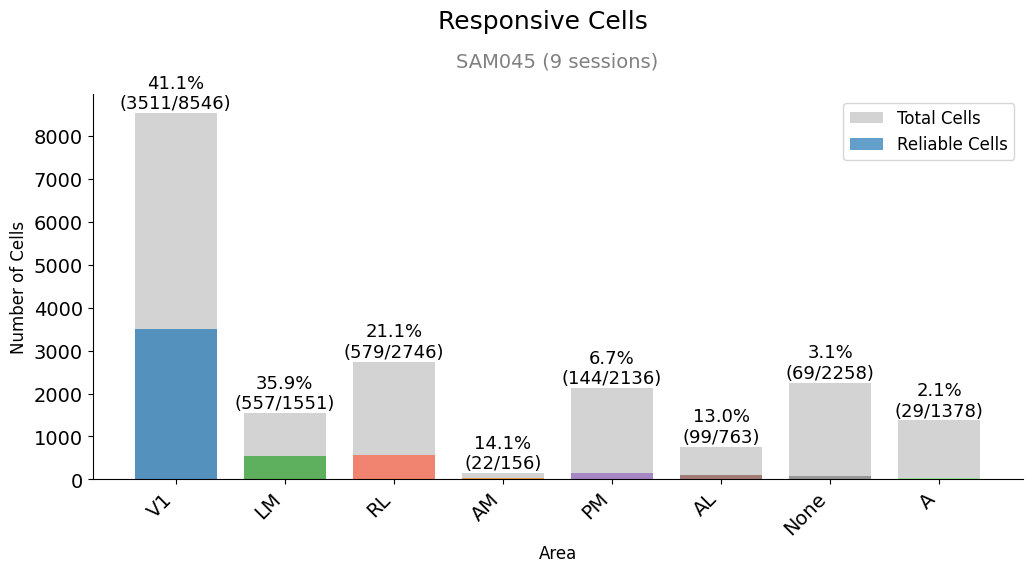

In [197]:
fig = viz.plot_responsive_bars(group_by='area')
# fig = SAM043_viz.plot_modulation_bars(group_by='session')

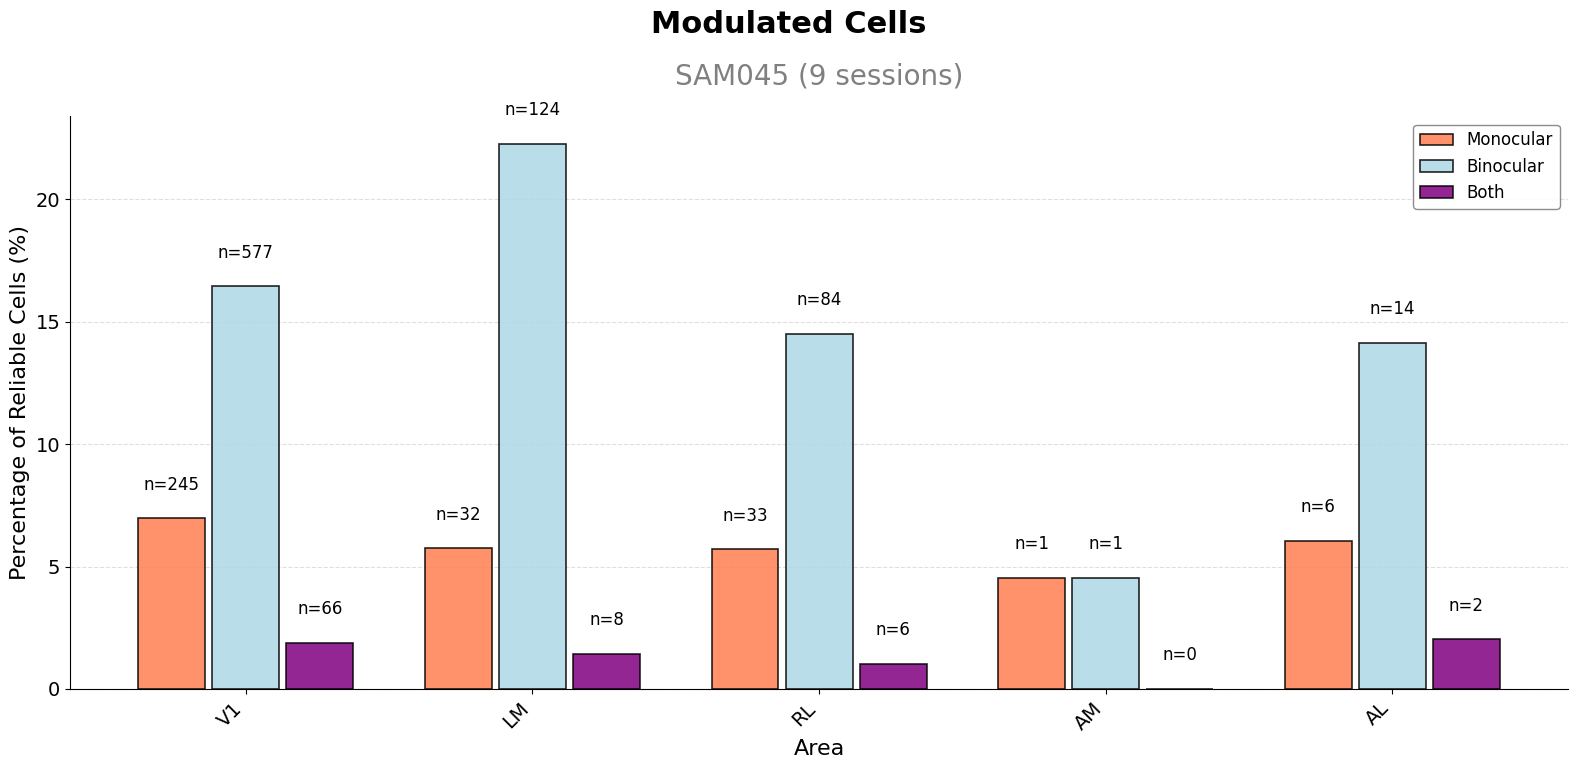

In [198]:
fig = viz.plot_modulation_bars(group_by='area')

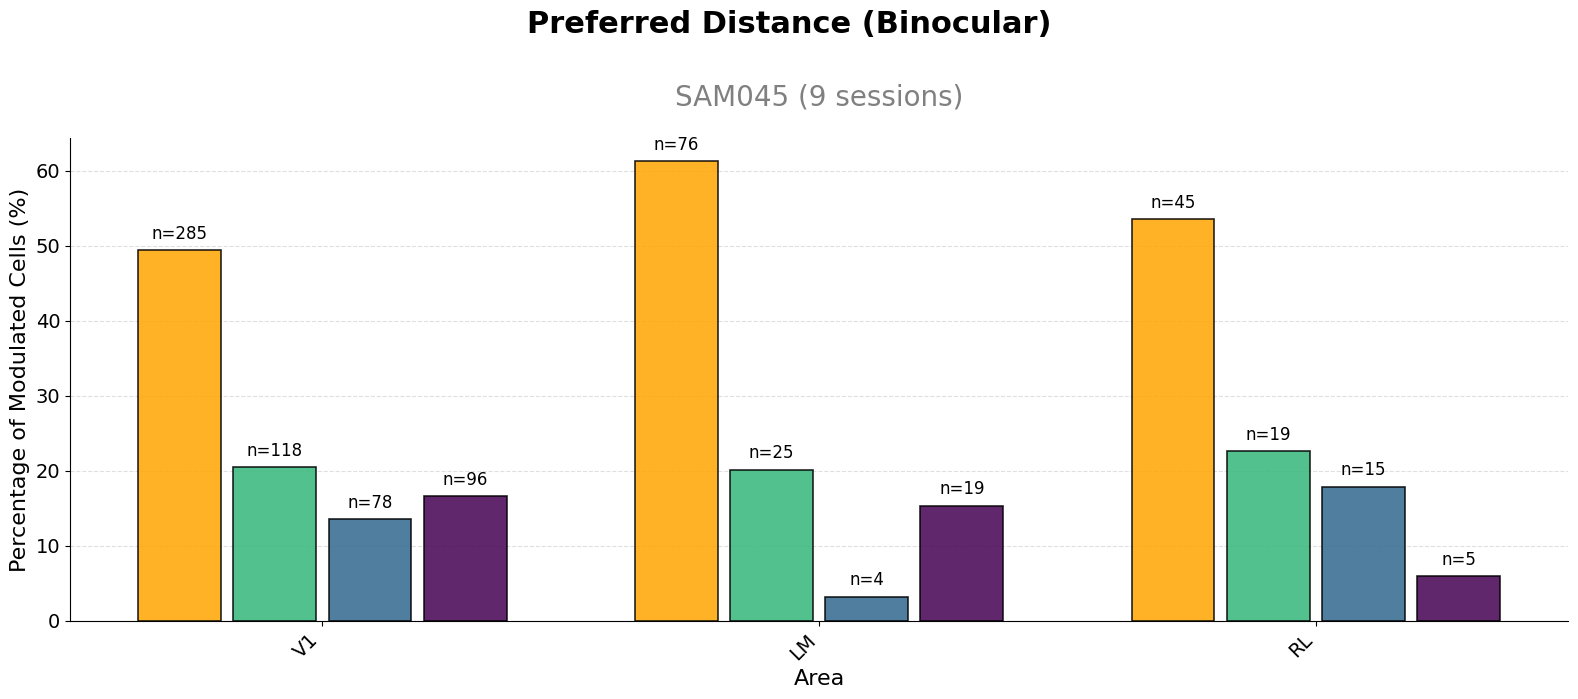

In [203]:
fig = viz.plot_distance_bars(group_by='area', condition='binocular', min_cells = 20)

# 3. Maps of cells

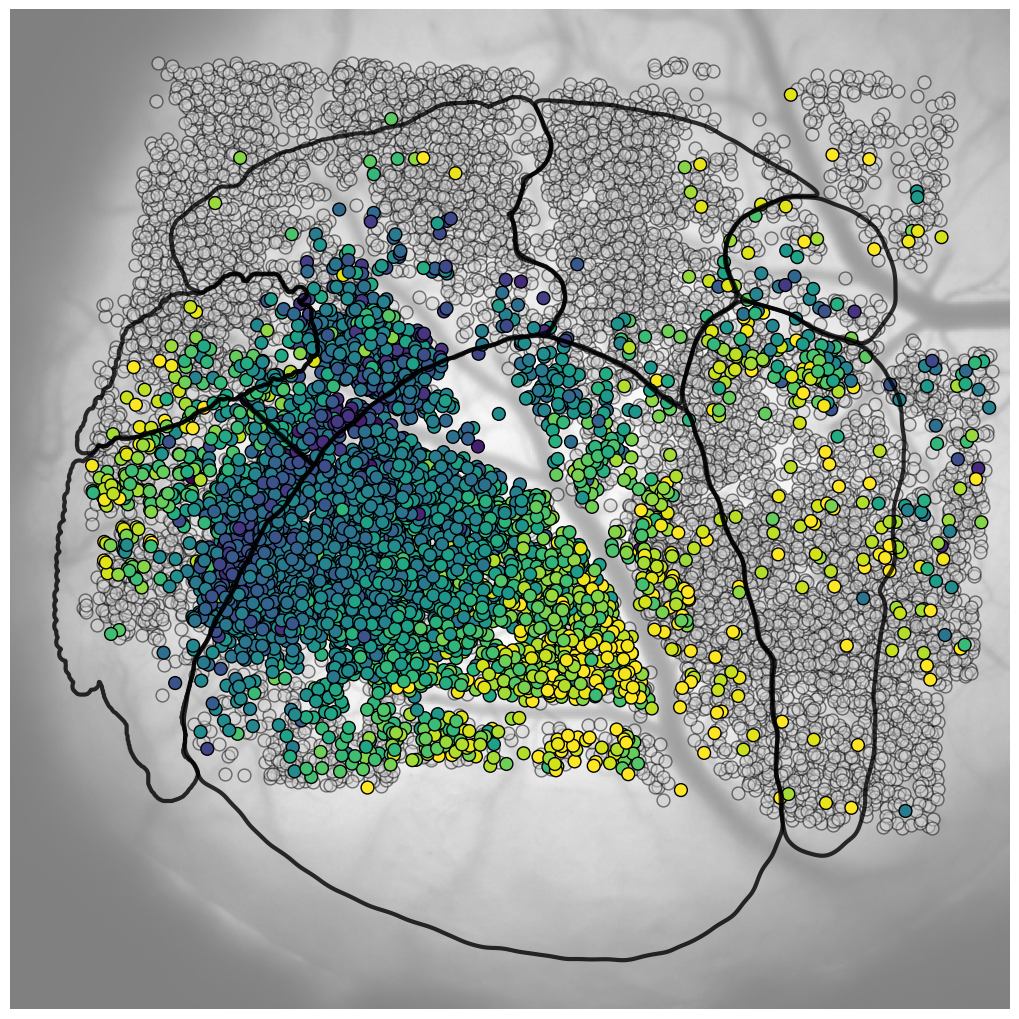

In [60]:
fig = viz.plot_cell_features(condition='reliable', feature='RF')

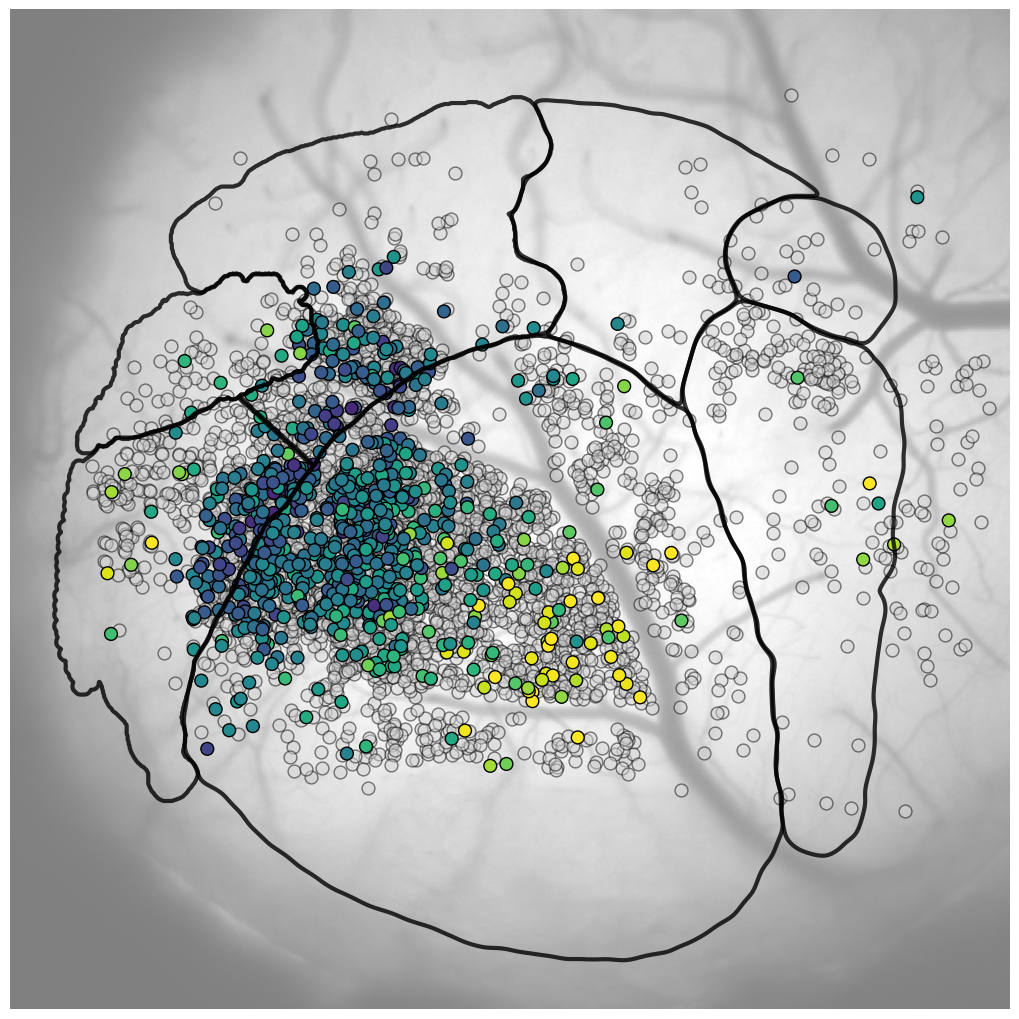

In [61]:
fig = viz.plot_cell_features(condition='binocular', feature='RF')

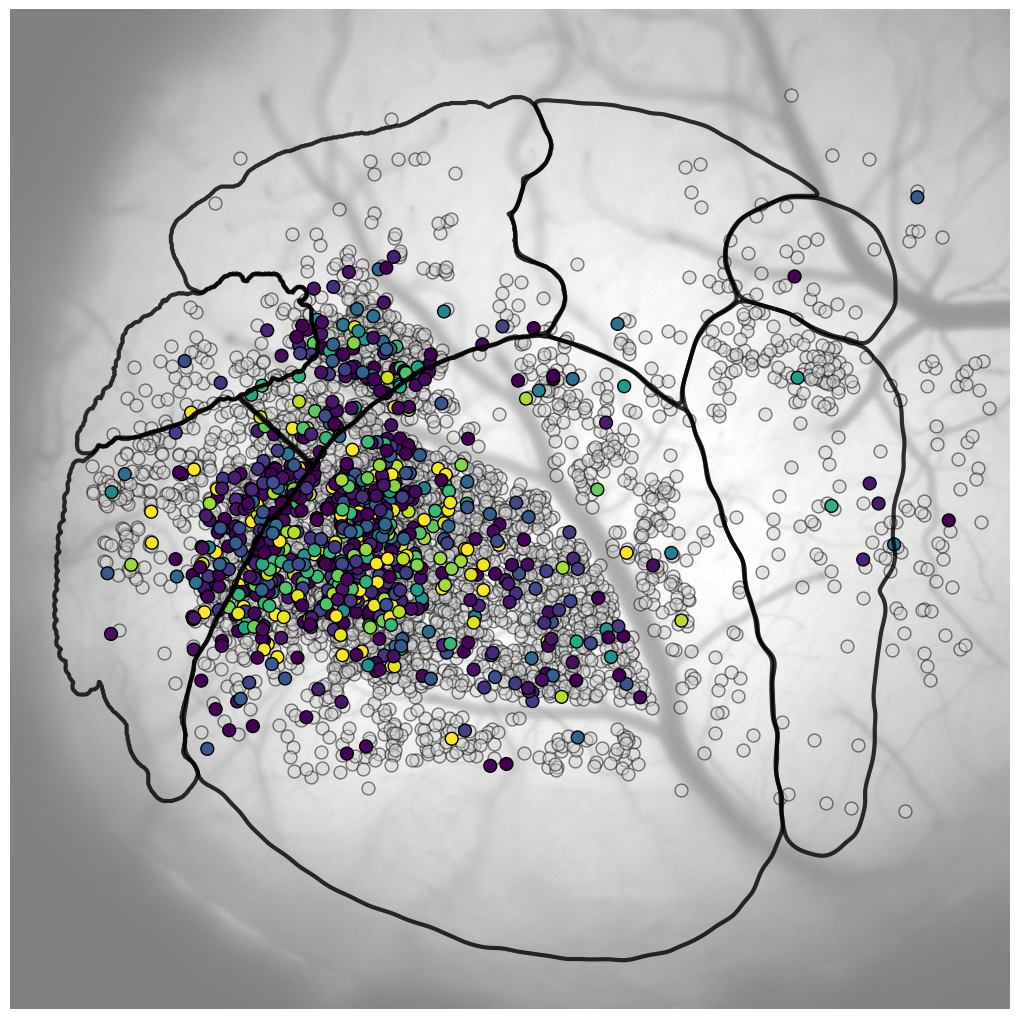

In [62]:
fig = viz.plot_cell_features(condition='binocular', feature='distance')

# 4. Are Areas Really different? 

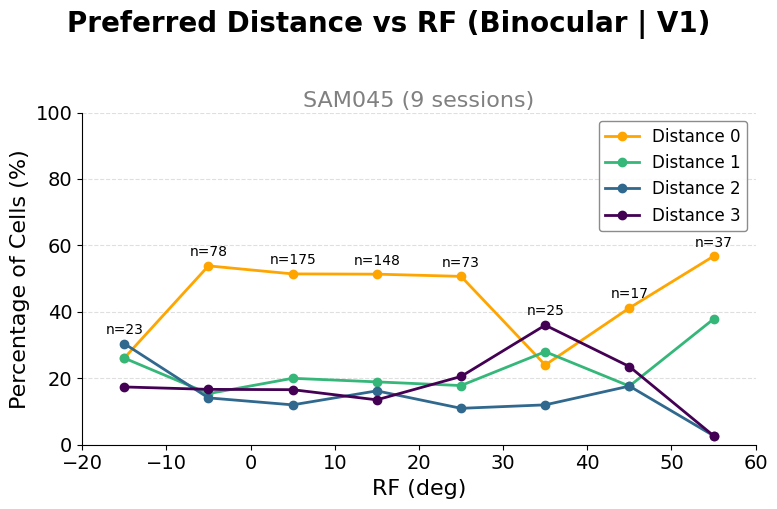

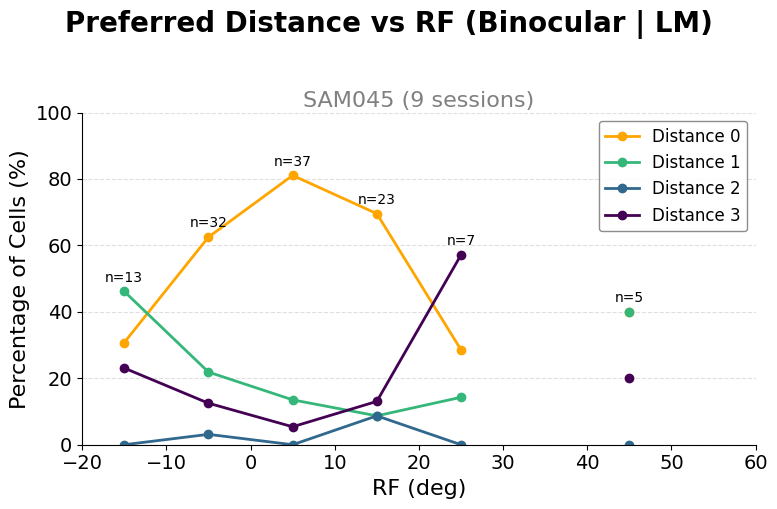

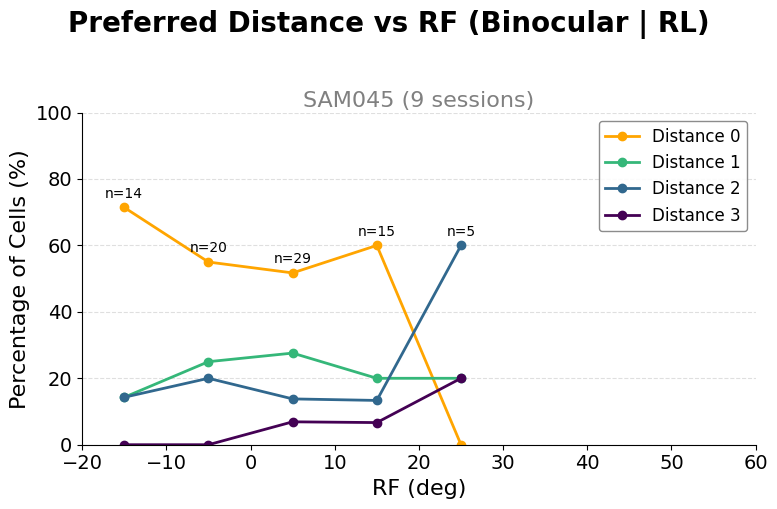

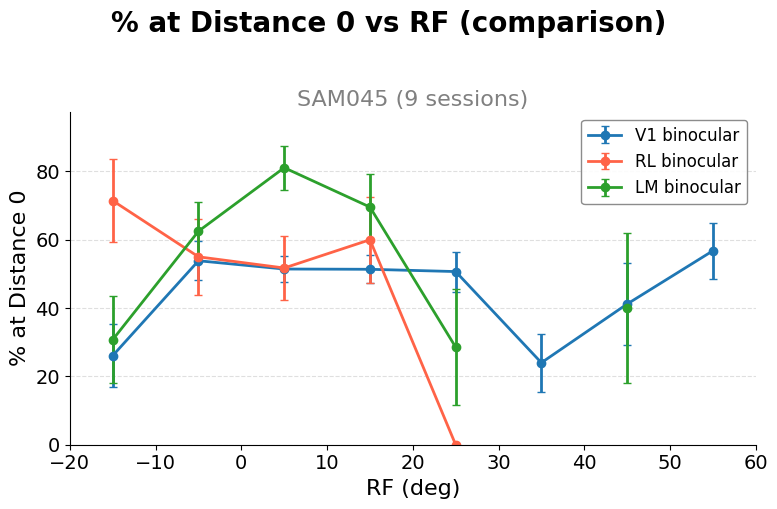

In [206]:
fig, ax = viz.plot_distance_pref_vs_rf(condition='binocular', area='V1',
                                       bin_width=10.0, min_cells_per_bin=5)
plt.show()


fig, ax = viz.plot_distance_pref_vs_rf(condition='binocular', area='LM',
                                       bin_width=10.0, min_cells_per_bin=5)
plt.show()

fig, ax = viz.plot_distance_pref_vs_rf(condition='binocular', area='RL',
                                       bin_width=10.0, min_cells_per_bin=5)
plt.show()

fig, ax = viz.plot_distance_pref_vs_rf_compare(
    groups=[('V1', 'binocular'), ('RL', 'binocular'), ('LM', 'binocular')], x_axis='RF', bin_width=10, min_cells_per_bin=5, pct_of_distance=0,show_stats=True)

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'SAM044 (9 sessions)'}, xlabel='RF (deg)', ylabel='% of Reliable Cells'>)

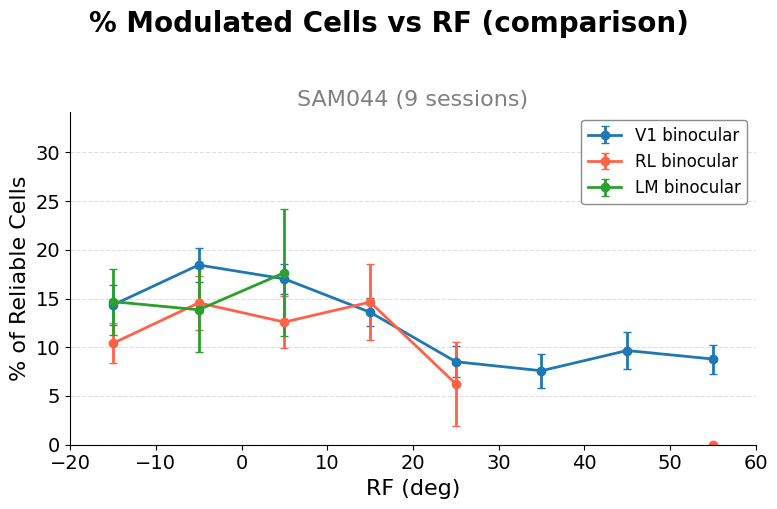

In [178]:
viz.plot_modulation_by_rf_compare([('V1', 'binocular'), ('RL', 'binocular'), ('LM', 'binocular')], show_stats=True)

# 5. Is there any trend with respect to retinotopy?

(<Figure size 1000x1000 with 2 Axes>, <Axes: >)

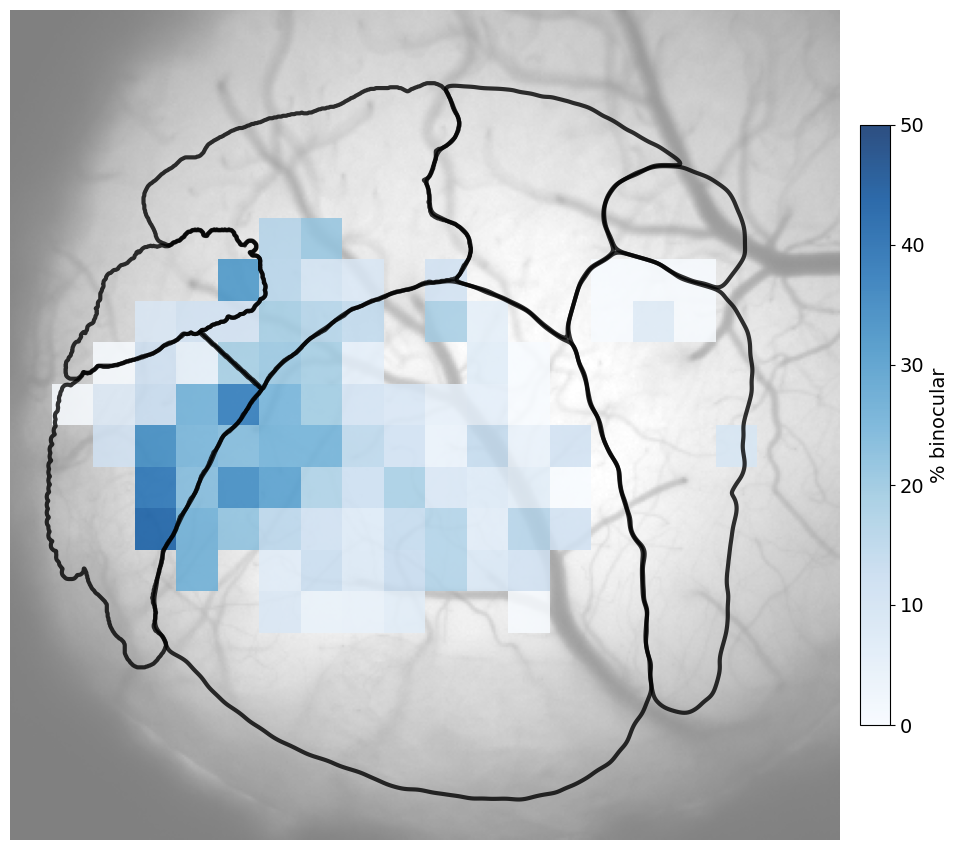

In [ ]:
viz.plot_cell_density(condition='binocular', feature='distance', n_bins=20, min_count=10)

(<Figure size 1000x1000 with 2 Axes>, <Axes: >)

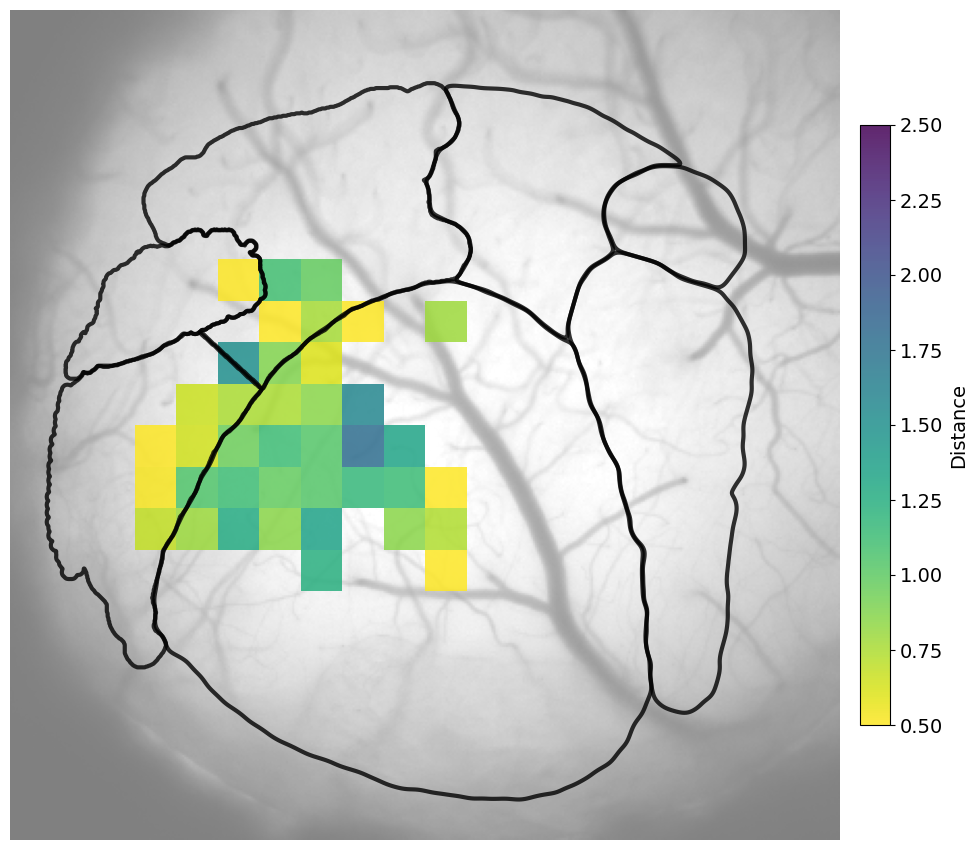

In [196]:
viz.plot_cell_density(condition='binocular', feature='distance', n_bins=20, min_count=5)

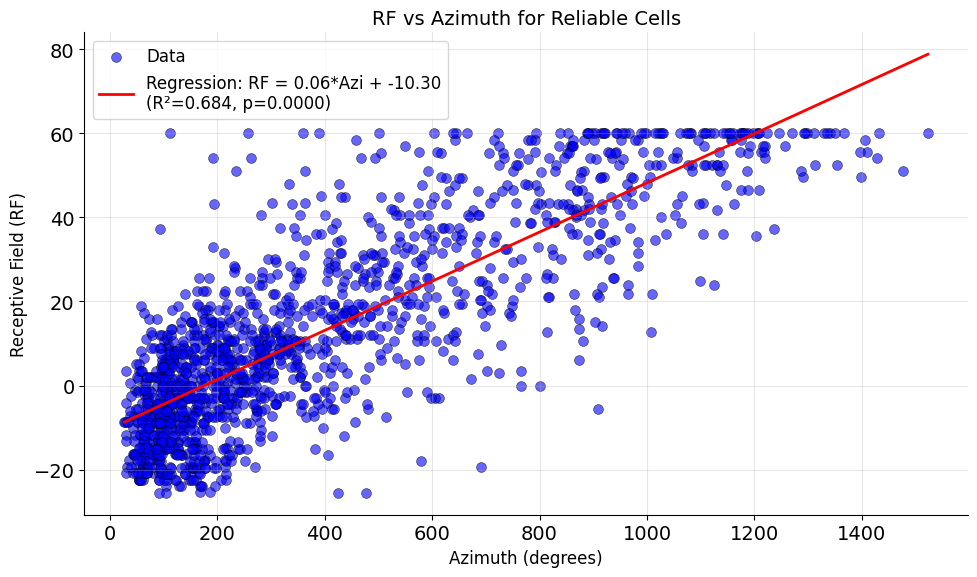

Plotted 1525 reliable cells
Regression: RF ≈ 0.06 * Azimuth + -10.30
R² = 0.6842, p-value = 0.0000


In [181]:
reliable_df = viz.filter_by_reliability(combined_df, reliable_type='reliable', threshold=0.95)
rf_values = np.array(reliable_df['RF'].values)
azi_values = np.array(reliable_df['azi'].values)

# Perform linear regression
from scipy import stats
slope, intercept, r_value, p_value, std_err = stats.linregress(azi_values, rf_values)

# Create regression line
azi_line = np.linspace(azi_values.min(), azi_values.max(), 100)
rf_line = slope * azi_line + intercept

# Create scatter plot with regression line
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(azi_values, rf_values, alpha=0.6, s=50, c='blue', edgecolors='black', linewidth=0.5, label='Data')
ax.plot(azi_line, rf_line, 'r-', linewidth=2, label=f'Regression: RF = {slope:.2f}*Azi + {intercept:.2f}\n(R²={r_value**2:.3f}, p={p_value:.4f})')
ax.set_xlabel('Azimuth (degrees)', fontsize=12)
ax.set_ylabel('Receptive Field (RF)', fontsize=12)
ax.set_title('RF vs Azimuth for Reliable Cells', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Plotted {len(rf_values)} reliable cells")
print(f"Regression: RF ≈ {slope:.2f} * Azimuth + {intercept:.2f}")
print(f"R² = {r_value**2:.4f}, p-value = {p_value:.4f}")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'SAM045 (9 sessions)'}, xlabel='azi (deg)', ylabel='Percentage of Cells (%)'>)

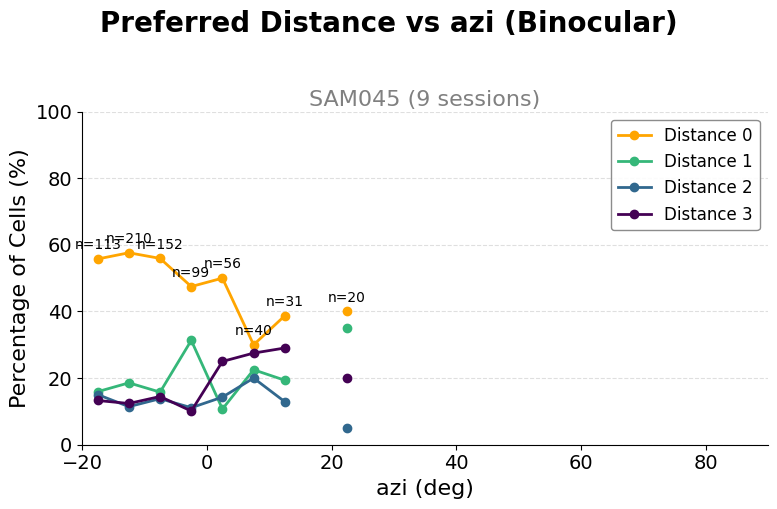

In [103]:
viz.plot_distance_pref_vs_rf(condition='binocular', x_axis='azi')

In [ ]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.data.WidefieldAligner import WidefieldAligner
from src.data.WidefieldTransformer import WidefieldMapper
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SingleSessionVisualizer, MultiSessionVisualizer
from src.viz.WidefieldVisualizer import WidefieldVisualizer
from src.workflows import load_dataframe

import numpy as np
import matplotlib.pyplot as plt
import pickle
import pandas as pd

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM045'
experiment_name = 'tiling_120um'

combined_df = load_dataframe(mouse_name=mouse_name, experiment_name=experiment_name)
session_df = (
    combined_df[combined_df['session_name'] == '260504_SAM045_tiling_1_120um']
    .drop(columns='session_name')
    .reset_index(drop=True)
)

multi_session_dir = r'D:/data-distance-coding-project/multi-session-data/'
multi_session_dir = os.path.join(multi_session_dir, f'SAM045_{experiment_name}')
alignment_name = f'SAM045_tiling_120um_alignment_parameters.pkl'
alignment_path = os.path.join(multi_session_dir, alignment_name)

with open(alignment_path, 'rb') as f:
    alignment_params = pickle.load(f)
    print(f"Alignment parameters loaded from {alignment_name}")

from src.data.WidefieldTransformer import WidefieldMapper
mapper = WidefieldMapper(alignment_params)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[ok] Loaded DataFrame from D:/data-distance-coding-project/multi-session-data\SAM045_tiling_120um\SAM045_tiling_120um_combined_sessions.pkl (19534 cells)
Alignment parameters loaded from SAM045_tiling_120um_alignment_parameters.pkl


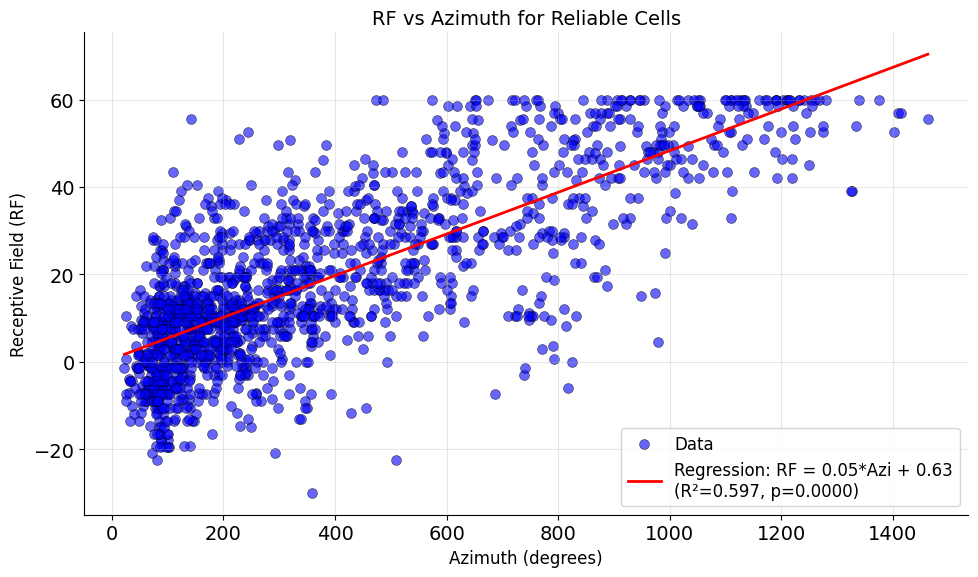

Plotted 1606 reliable cells
Regression: RF ≈ 0.05 * Azimuth + 0.63
R² = 0.5969, p-value = 0.0000


In [69]:
reliable_df = viz.filter_by_reliability(combined_df, reliable_type='reliable', threshold=0.95)
rf_values = np.array(reliable_df['RF'].values)
azi_values = np.array(reliable_df['azi'].values)

# Perform linear regression
from scipy import stats
slope, intercept, r_value, p_value, std_err = stats.linregress(azi_values, rf_values)

# Create regression line
azi_line = np.linspace(azi_values.min(), azi_values.max(), 100)
rf_line = slope * azi_line + intercept

# Create scatter plot with regression line
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(azi_values, rf_values, alpha=0.6, s=50, c='blue', edgecolors='black', linewidth=0.5, label='Data')
ax.plot(azi_line, rf_line, 'r-', linewidth=2, label=f'Regression: RF = {slope:.2f}*Azi + {intercept:.2f}\n(R²={r_value**2:.3f}, p={p_value:.4f})')
ax.set_xlabel('Azimuth (degrees)', fontsize=12)
ax.set_ylabel('Receptive Field (RF)', fontsize=12)
ax.set_title('RF vs Azimuth for Reliable Cells', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Plotted {len(rf_values)} reliable cells")
print(f"Regression: RF ≈ {slope:.2f} * Azimuth + {intercept:.2f}")
print(f"R² = {r_value**2:.4f}, p-value = {p_value:.4f}")

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'SAM045 (9 sessions)'}, xlabel='Altitude (deg)', ylabel='Reliability (corr)'>)

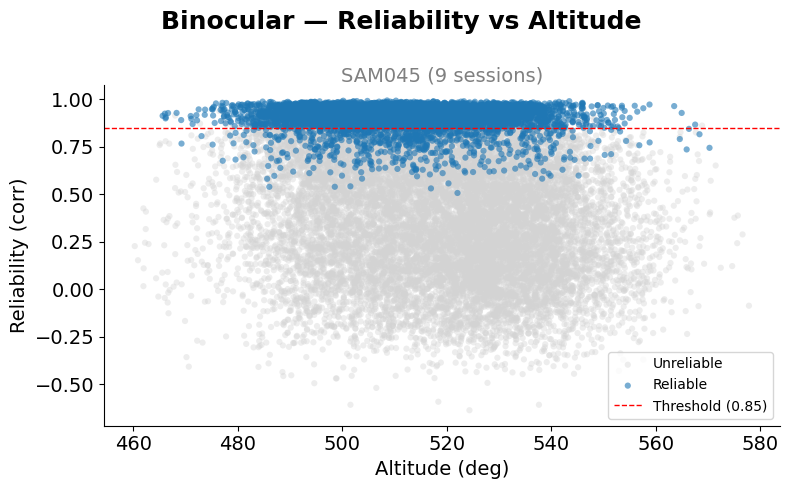

In [26]:
viz.plot_reliability_scatter(rf_axis='alt')

In [52]:
reliable_df = viz.filter_by_reliability(combined_df, reliable_type='reliable', threshold=0.85)
azi_vals = reliable_df['azi'].values

(array([1454., 1191.,  738.,  451.,  301.,  324.,  246.,  167.,  105.,
          33.]),
 array([   9.41855893,  155.27814059,  301.13772224,  446.99730389,
         592.85688555,  738.7164672 ,  884.57604886, 1030.43563051,
        1176.29521216, 1322.15479382, 1468.01437547]),
 <BarContainer object of 10 artists>)

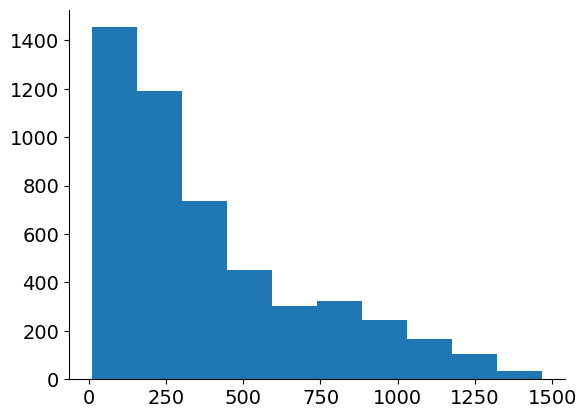

In [53]:
plt.hist(azi_vals)

In [57]:
data = np.load(r'D:\data-distance-coding-project\multi-session-data\SAM045_tiling_120um\retinotopy.npz')

def azi2degree(azi):

    old_min = np.percentile(data['azimuth_map'], 5)
    old_max = np.percentile(data['azimuth_map'], 95)
    new_min, new_max = -20, 100

    return (azi - old_min) / (old_max - old_min) * (new_max - new_min) + new_min

min_degree = azi2degree(0)
max_degree = azi2degree(1250)

print('min degree', min_degree)
print('max degree', max_degree)

min degree -37.493282653566276
max degree 87.12586144378179


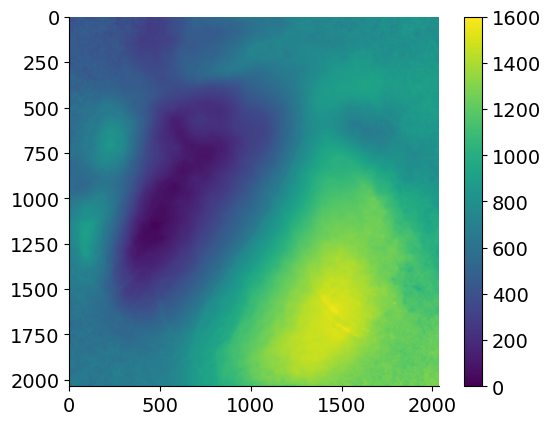

In [40]:
plt.imshow(data['azimuth_map'])
plt.colorbar()

In [39]:
print(np.percentile(data['azimuth_map'], 5))
print(np.percentile(data['azimuth_map'], 95))

175.46744904519988
1379.1348396896526


(<Figure size 1000x500 with 2 Axes>,
 {'positions': array([15, 16, 17, 18, 19, 20, 21]),
  'fractions': array([0.41125338, 0.41083548, 0.41083548, 0.41083548, 0.41083548,
         0.41083548, 0.41074564]),
  'counts_total': array([8513, 8546, 8546, 8546, 8546, 8546, 8543]),
  'counts_reliable': array([3501, 3511, 3511, 3511, 3511, 3511, 3509])})

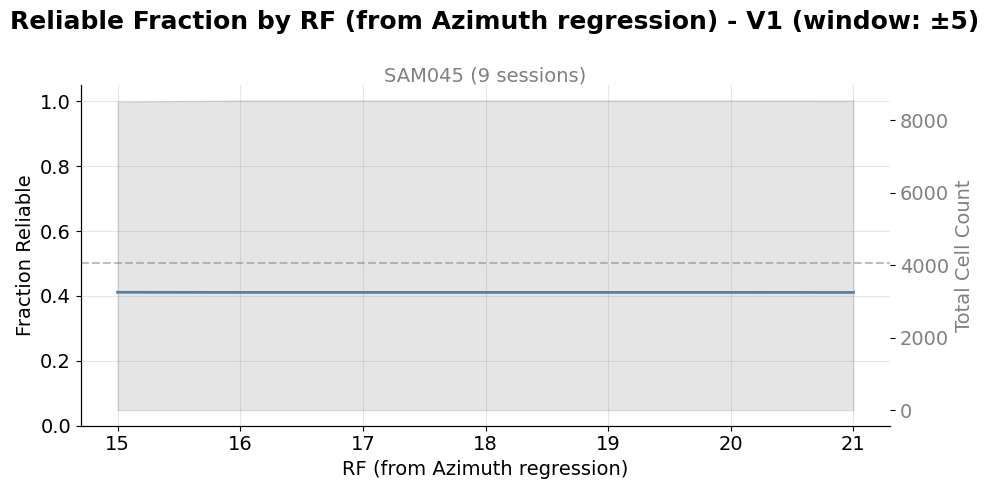

In [27]:
viz.plot_reliability_fraction(rf_axis='azi', area = 'V1')

(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'SAM041 (9 sessions)'}, xlabel='Azimuth', ylabel='RF — Monocular'>)

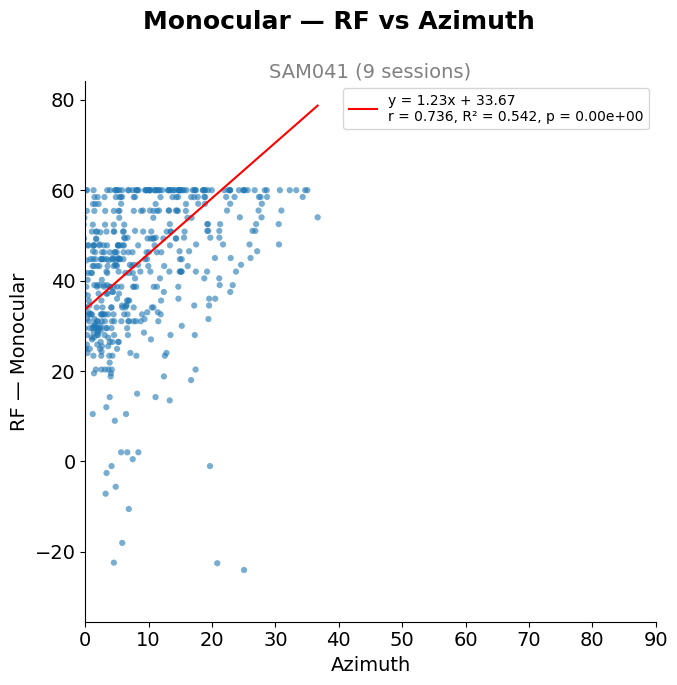

In [119]:
SAM041_viz.plot_rf_vs_azi(condition='monocular')